lab5
\
jaber alsaikhan
\
2240006539

# ARTI 404 - Image Processing
## Lab 5: Spatial Filtering - Smoothing and Sharpening

Outcome#2: Write a program that implements fundamental image processing
algorithms.

The manual's unsharp masking step reads `images/Parrot.png`. That file is not
part of this repository, so Step 0 checks for it and, if it is missing,
writes a stand-in from skimage's built-in sample data (`coffee.png`). Drop the
course's `Parrot.png` into `labs/lab5/images/` and the notebook uses it
instead. The assessment tasks say "an image of your choice"; Step 0 saves those
images (`cameraman.png`, `astronaut.png`, `moon.png`) into the same folder, so
the Lab 5 folder contains every image the notebook uses.

In [1]:
import os

import cv2
import numpy as np
import matplotlib.pyplot as plt

from skimage import data, io

## Step 0: Prepare the working images on disk

In [2]:
# __file__ is undefined inside a notebook kernel, which starts in the notebook's
# own directory, so fall back to the working directory there.
try:
    HERE = os.path.dirname(os.path.abspath(__file__))
except NameError:
    HERE = os.getcwd()

IMAGES_DIR = os.path.join(HERE, "images")
os.makedirs(IMAGES_DIR, exist_ok=True)

PARROT_PATH = os.path.join(IMAGES_DIR, "Parrot.png")
if os.path.exists(PARROT_PATH):
    UNSHARP_PATH = PARROT_PATH
else:
    UNSHARP_PATH = os.path.join(IMAGES_DIR, "coffee.png")  # stands in for Parrot.png
    io.imsave(UNSHARP_PATH, data.coffee(), check_contrast=False)

# Images of our choice for the assessment tasks.
BOX_PATH = os.path.join(IMAGES_DIR, "cameraman.png")
GAUSS_PATH = os.path.join(IMAGES_DIR, "astronaut.png")
LAPLACE_PATH = os.path.join(IMAGES_DIR, "moon.png")
for path, image in [(BOX_PATH, data.camera()), (GAUSS_PATH, data.astronaut()), (LAPLACE_PATH, data.moon())]:
    io.imsave(path, image, check_contrast=False)

print("Unsharp masking image:", os.path.basename(UNSHARP_PATH))
print("Images dir:", os.path.normpath(IMAGES_DIR))

Unsharp masking image: coffee.png
Images dir: c:\Users\jaber\OneDrive\Desktop\Image Processing\labs\lab5\images


## Task#1: Unsharp Masking

Unsharp masking sharpens an image by adding back the detail that a blur
removes. The Gaussian blur keeps only the low frequencies, so
`image - blurred` is a "mask" containing the edges and fine texture.
Adding `amount` times that mask to the original boosts the edges:

`sharpened = image + amount * (image - blurred)`

`sigma` controls how wide the detail being boosted is, and `amount` controls
how strongly it is boosted. The image is converted to float in [0, 1] first so
the subtraction can go negative without wrapping around, and the result is
clipped back to [0, 1].

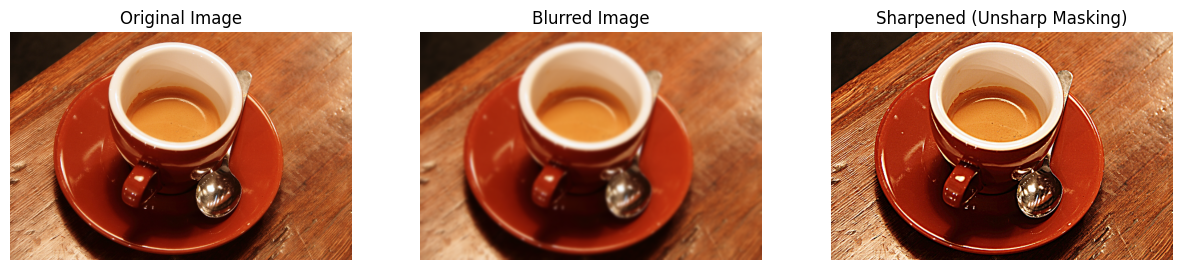

In [3]:
# Read the image
image = cv2.imread(UNSHARP_PATH)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convert from BGR to RGB
# Gaussian sigma
sigma = 2
# parameter
amount = 1.5
# Convert image to float32 for processing
image_float = image.astype(np.float32) / 255.0
# Apply Gaussian blur
blurred = cv2.GaussianBlur(image_float, (0, 0), sigmaX=sigma, sigmaY=sigma)
# Perform Unsharp Masking
sharpened = np.clip(image_float + amount * (image_float - blurred), 0, 1)
# Plot original, blurred, and sharpened images
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(image)
ax[0].set_title("Original Image")
ax[0].axis("off")
ax[1].imshow(blurred)
ax[1].set_title("Blurred Image")
ax[1].axis("off")
ax[2].imshow(sharpened)
ax[2].set_title("Sharpened (Unsharp Masking)")
ax[2].axis("off")
plt.show()

The differences are easier to see up close. The crop below is the same region
of all three images: the blurred one loses the fine texture, and the sharpened
one has crisper edges and more pronounced texture than the original.

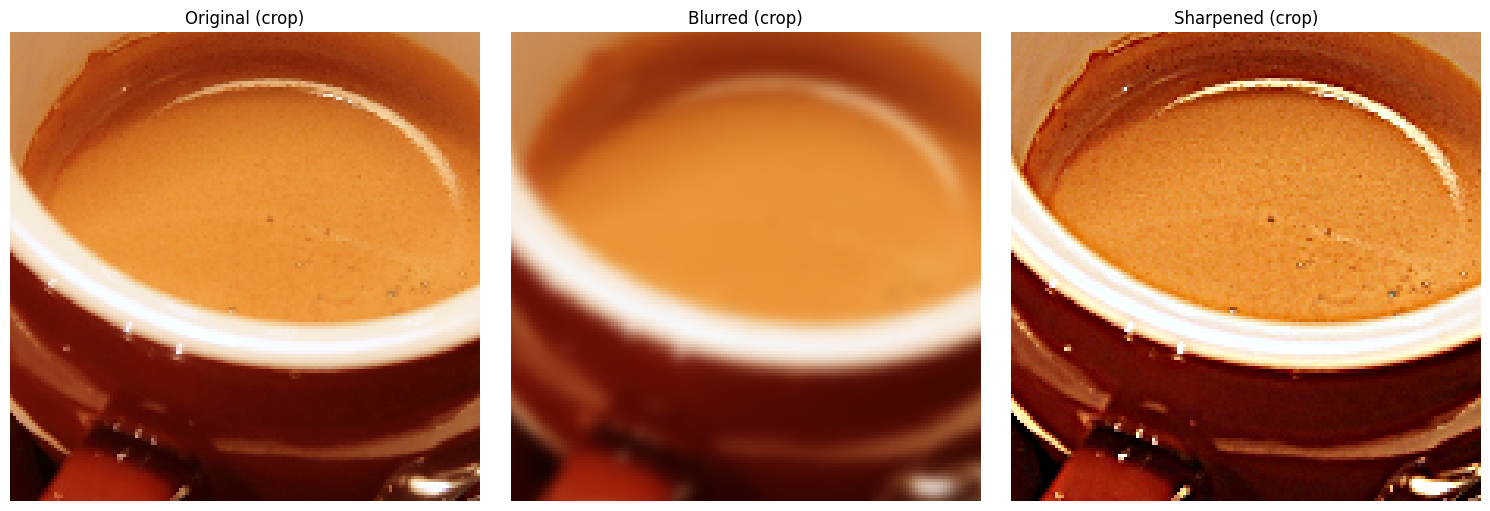

In [4]:
h, w = image.shape[:2]
crop = (slice(h // 4, h // 4 + 150), slice(w // 3, w // 3 + 150))

fig, ax = plt.subplots(1, 3, figsize=(15, 5), layout="constrained")
for a, im, title in zip(ax, [image_float, blurred, sharpened], ["Original (crop)", "Blurred (crop)", "Sharpened (crop)"]):
    a.imshow(im[crop])
    a.set_title(title)
    a.axis("off")
plt.show()

## Assessment

### Task#1: 7x7 box filter

A box (mean) filter replaces every pixel with the average of its
neighbourhood. The kernel is a 7x7 array of ones divided by 49, so its weights
sum to 1 and the overall brightness is preserved. `cv2.filter2D` convolves the
image with the kernel (for a symmetric kernel, correlation and convolution give
the same result). `cv2.blur(img, (7, 7))` gives an identical result; the check
below confirms it.

Kernel sum: 1.000
Same as cv2.blur: True


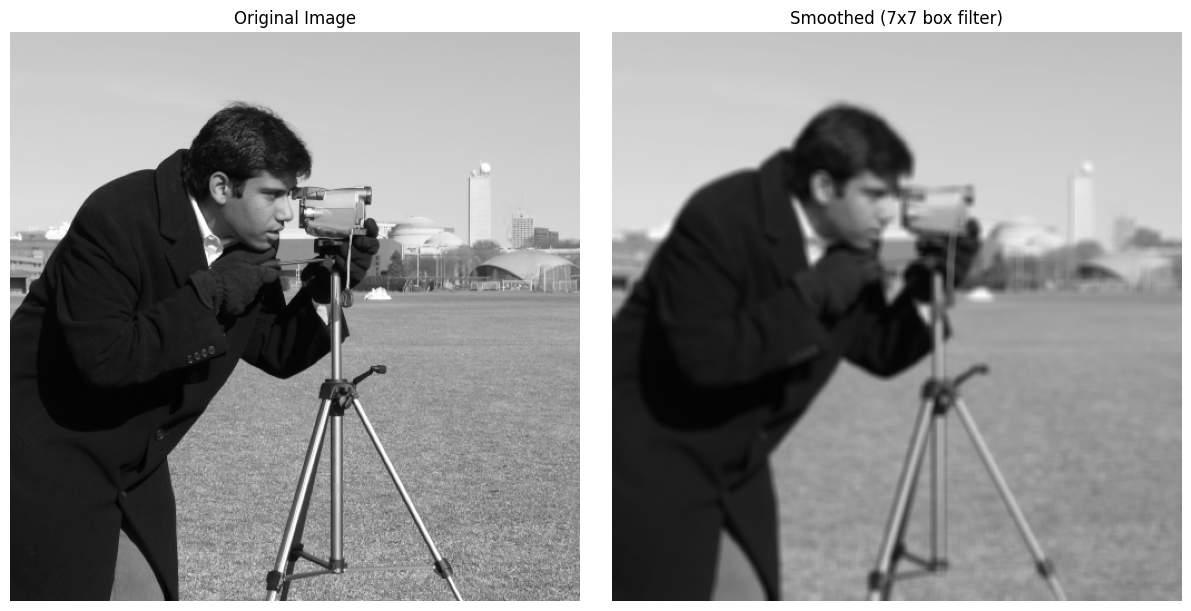

In [5]:
img = cv2.imread(BOX_PATH, cv2.IMREAD_GRAYSCALE)

box_kernel = np.ones((7, 7), np.float32) / 49
smoothed = cv2.filter2D(img, -1, box_kernel)

print(f"Kernel sum: {box_kernel.sum():.3f}")
print("Same as cv2.blur:", np.array_equal(smoothed, cv2.blur(img, (7, 7))))

fig, ax = plt.subplots(1, 2, figsize=(12, 6), layout="constrained")
ax[0].imshow(img, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("Original Image")
ax[1].imshow(smoothed, cmap="gray", vmin=0, vmax=255)
ax[1].set_title("Smoothed (7x7 box filter)")
for a in ax:
    a.axis("off")
plt.show()

The box filter removes noise and fine detail (the grass texture and the
camera's edges blur), but because every neighbour gets the same weight it also
smears edges evenly in all directions.

### Task#2: 5x5 and 21x21 Gaussian filters

A Gaussian filter also averages a neighbourhood, but weights nearby pixels more
than distant ones, so it blurs more smoothly than a box filter. With `sigma=0`
OpenCV derives sigma from the kernel size
(`sigma = 0.3 * ((ksize - 1) * 0.5 - 1) + 0.8`), so the 21x21 kernel is both
larger and wider, and blurs far more than the 5x5 one.

5x5: sigma = 1.10
21x21: sigma = 3.50


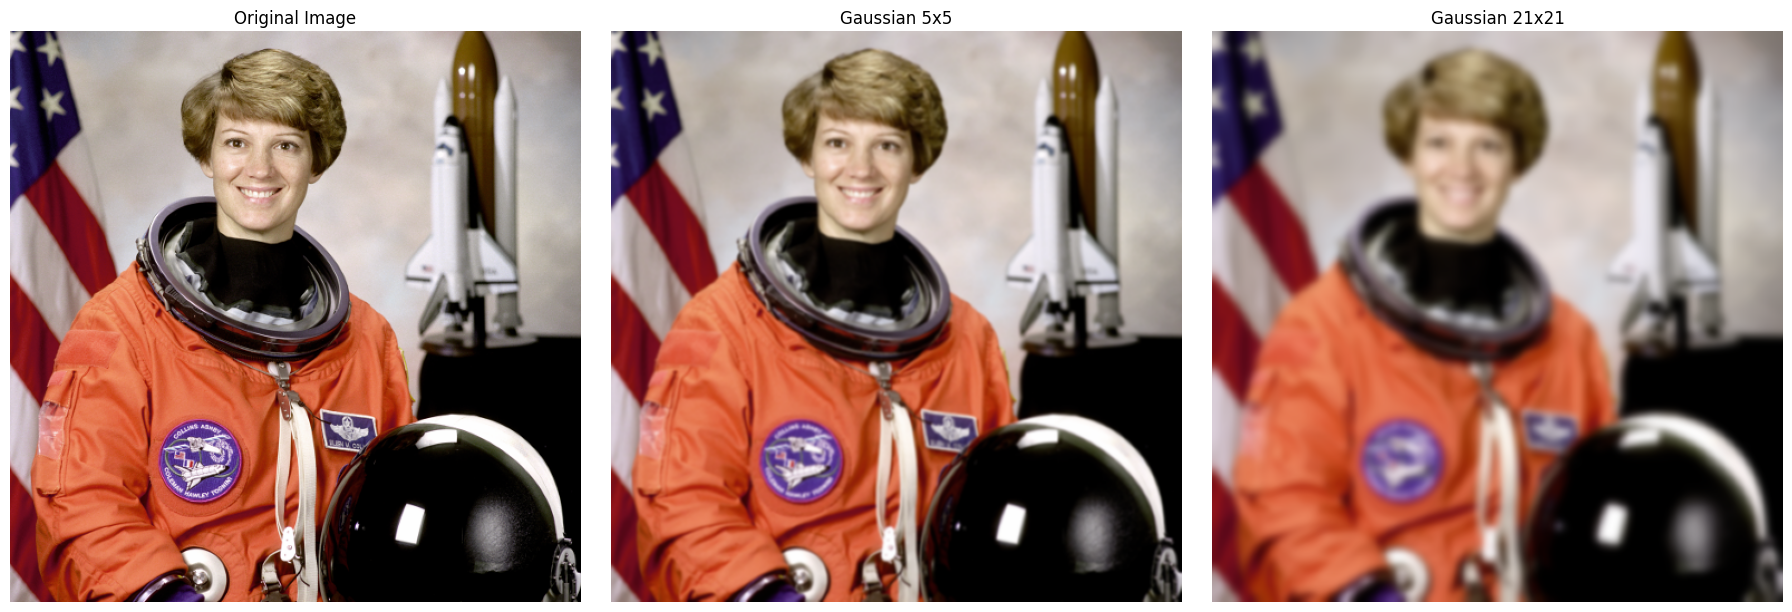

In [6]:
img = cv2.cvtColor(cv2.imread(GAUSS_PATH), cv2.COLOR_BGR2RGB)

gauss_5 = cv2.GaussianBlur(img, (5, 5), 0)
gauss_21 = cv2.GaussianBlur(img, (21, 21), 0)

for k in (5, 21):
    print(f"{k}x{k}: sigma = {0.3 * ((k - 1) * 0.5 - 1) + 0.8:.2f}")

fig, ax = plt.subplots(1, 3, figsize=(18, 6), layout="constrained")
for a, im, title in zip(ax, [img, gauss_5, gauss_21], ["Original Image", "Gaussian 5x5", "Gaussian 21x21"]):
    a.imshow(im)
    a.set_title(title)
    a.axis("off")
plt.show()

The 5x5 filter only softens fine detail slightly; the 21x21 filter removes
most of it and leaves only the large shapes and colour regions.

### Task#3: Sharpening with a 3x3 Laplacian filter

The Laplacian is a second-derivative operator: it is close to zero in flat
regions and large where intensity changes abruptly, so it responds to edges
and fine detail. `cv2.Laplacian` with `ksize=1` applies the standard 3x3
kernel

```
0  1  0
1 -4  1
0  1  0
```

Because the centre coefficient is negative, subtracting the Laplacian from the
image sharpens it: `sharpened = image - laplacian`. (`ksize=3` is also a 3x3
kernel, `[[2, 0, 2], [0, -8, 0], [2, 0, 2]]`, which gives a stronger
response; the textbook kernel above is used here.) `cv2.CV_32F` keeps the
negative values of the Laplacian instead of clipping them to 0.

Laplacian range: -0.635 to 0.631


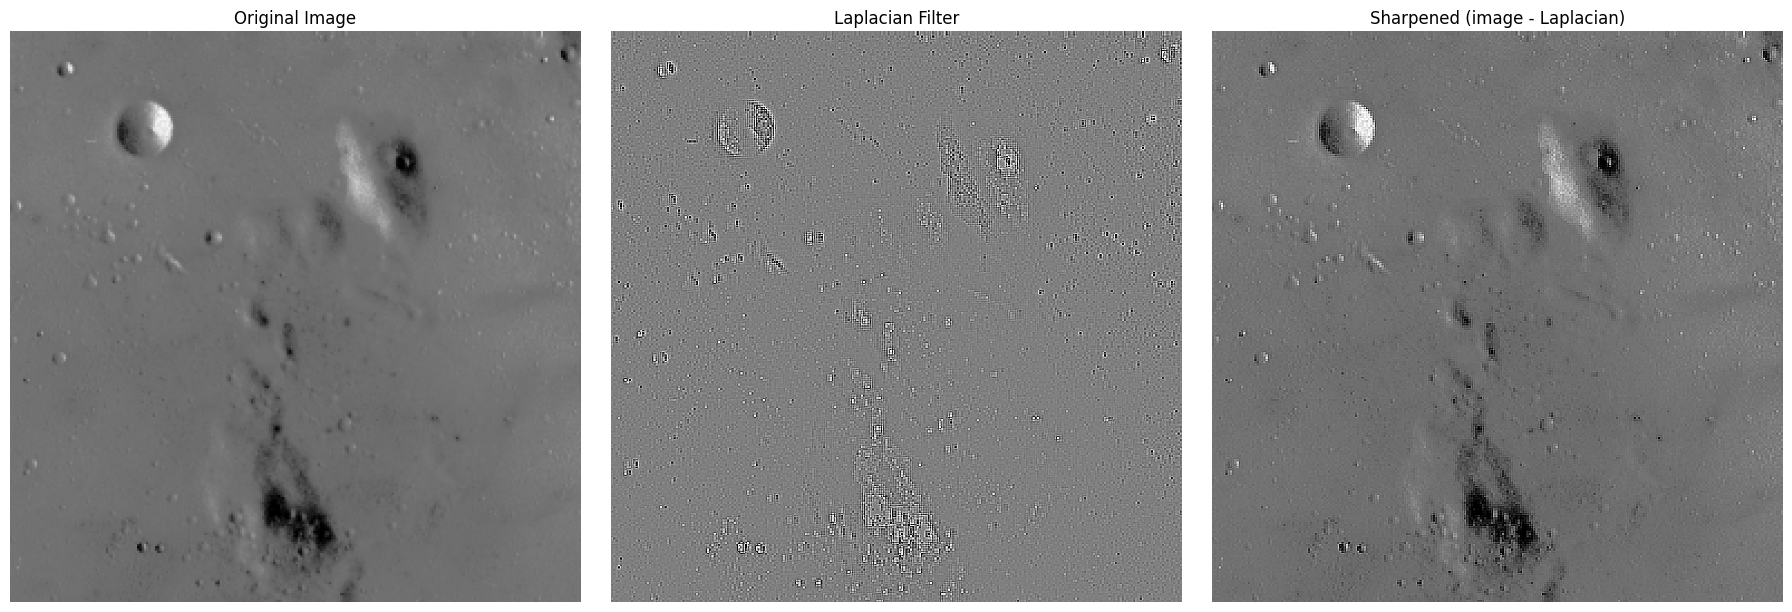

In [7]:
# Read the image
img = cv2.imread(LAPLACE_PATH, cv2.IMREAD_GRAYSCALE)
# Convert image to float32
image_float = img.astype(np.float32) / 255.0
# Use the cv2.Laplacian() function (ksize=1 -> 3x3 kernel [[0,1,0],[1,-4,1],[0,1,0]])
laplacian = cv2.Laplacian(image_float, cv2.CV_32F, ksize=1)
# Sharpen the image
sharpened = np.clip(image_float - laplacian, 0, 1)

print(f"Laplacian range: {laplacian.min():.3f} to {laplacian.max():.3f}")

# The Laplacian is signed, so show it centred on 0 (gray = 0, dark = negative, bright = positive).
# A few extreme values would wash out the rest, so the display range is the 99th percentile.
lim = np.percentile(np.abs(laplacian), 99)

fig, ax = plt.subplots(1, 3, figsize=(18, 6), layout="constrained")
ax[0].imshow(image_float, cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Original Image")
ax[1].imshow(laplacian, cmap="gray", vmin=-lim, vmax=lim)
ax[1].set_title("Laplacian Filter")
ax[2].imshow(sharpened, cmap="gray", vmin=0, vmax=1)
ax[2].set_title("Sharpened (image - Laplacian)")
for a in ax:
    a.axis("off")
plt.show()

The Laplacian image is flat gray almost everywhere and lights up only along
the crater rims. Subtracting it from the original makes those rims and the
surface texture noticeably crisper, while flat regions stay unchanged.

## Resources

- <https://docs.opencv.org/4.x/d4/d13/tutorial_py_filtering.html>
- <https://datacarpentry.github.io/image-processing/06-blurring.html>